# Risco de atraso em pedidos da Olist

## Desafio de negócio

Identificar, **logo após a aprovação do pagamento**, quais pedidos possuem maior risco de serem entregues depois do prazo prometido.

### Objetivos

- estimar futuramente a probabilidade de atraso de cada pedido;
- explicar os principais fatores associados ao risco;
- apoiar uma decisão operacional baseada em custos e capacidade.

> Este notebook não pretende realizar um EDA completo. Ele apresenta uma experiência reduzida e orientada por hipóteses, adequada para uma aula curta.

## Roteiro da experiência

1. Definir o alvo e o instante da previsão.
2. Carregar e verificar as tabelas.
3. Integrar os dados mantendo **uma linha por pedido**.
4. Investigar cinco perguntas orientadas por hipóteses.
5. Registrar conclusões e possíveis features.

**Pergunta central:** quais características disponíveis após a aprovação do pagamento estão associadas ao atraso?

In [7]:
# Bibliotecas para caminhos, manipulação de dados e visualização.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


# Configura a exibição das tabelas e o estilo dos gráficos.
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", palette="Blues_r")


# Define os caminhos principais do projeto.
ROOT = Path.cwd().parents[0]
DATA_DIR = ROOT / "data"


# Exibe o caminho da pasta onde estão os dados.
DATA_DIR

WindowsPath('c:/Users/toksg/OneDrive/Documentos/Importante/Faculdade/2026.2/Machine-Learning-Projetos/olist/data')

## 1. Instante da previsão e risco de data leakage

O modelo deverá gerar a previsão no instante `order_approved_at`. Assim, somente informações já conhecidas até esse momento poderão ser usadas como features.

| Disponível na previsão | Informação futura (não usar como feature) |
|---|---|
| data da compra e aprovação | data de envio à transportadora |
| prazo prometido | data real da entrega |
| cliente e localização | avaliação e comentário do cliente |
| itens, vendedores, preço e frete | status ou eventos posteriores |

> A data real da entrega será utilizada apenas para construir o target. Ela não poderá entrar como variável explicativa do modelo.

## 2. Carregamento das tabelas

Utilizaremos quatro tabelas obrigatórias para o nosso cenário

In [8]:
# Mapeia os nomes dos datasets para seus arquivos CSV.
FILES = {
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "customers": "olist_customers_dataset.csv",
}

# Lista as colunas que devem ser interpretadas como datas.
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

# Carrega a base de pedidos, convertendo automaticamente as colunas de data.
orders = pd.read_csv(
    DATA_DIR / "raw" / FILES["orders"],
    parse_dates=date_columns,
)

# Carrega as bases de itens dos pedidos e clientes.
items = pd.read_csv(DATA_DIR / "raw" / FILES["items"])
customers = pd.read_csv(DATA_DIR / "raw" / FILES["customers"])

# Exibe a quantidade de linhas e colunas de cada base carregada.
print("Pedidos:", orders.shape)
print("Itens:", items.shape)
print("Clientes:", customers.shape)

Pedidos: (99441, 8)
Itens: (112650, 7)
Clientes: (99441, 5)


## 3. Construção do alvo

Para simplificar a experiência, usaremos apenas pedidos com status `delivered` e data real de entrega conhecida.


$$
is\_late = 1 \quad \text{se entrega real > entrega prometida}
$$


In [9]:
# Seleciona apenas os pedidos que podem ser utilizados para construir
# o histórico de entregas atrasadas e realizadas dentro do prazo.
delivered_orders = orders.loc[
    # Mantém somente pedidos que foram efetivamente entregues.
    orders["order_status"].eq("delivered")

    # Remove pedidos sem a data real em que o cliente recebeu a compra.
    # Essa data é necessária para saber se o pedido atrasou.
    & orders["order_delivered_customer_date"].notna()

    # Remove pedidos sem a data de entrega prometida ao cliente.
    # Sem essa informação, não é possível comparar o previsto com o realizado.
    & orders["order_estimated_delivery_date"].notna()

    # Mantém somente pedidos com a data de aprovação do pagamento.
    # Esse é o momento definido para realizar a previsão.
    & orders["order_approved_at"].notna()
].copy()  # Cria uma cópia independente para evitar alterações no DataFrame original.


# Cria a variável-alvo do problema:
# 1 → pedido entregue depois da data prometida;
# 0 → pedido entregue dentro do prazo ou antes da data prometida.
delivered_orders["is_late"] = (
    delivered_orders["order_delivered_customer_date"] > delivered_orders["order_estimated_delivery_date"]
).astype("int8")  # Armazena 0 e 1 usando um tipo inteiro que ocupa menos memória.


# Apresenta a quantidade total de pedidos antes da aplicação dos filtros.
print(f"Pedidos originais: {len(orders):,}")


# Apresenta quantos pedidos permaneceram após aplicação do filtro
print(f"Pedidos filtrados: {len(delivered_orders):,}")


# Mostra a quantidade de pedidos em cada classe:
# 0 = entregue no prazo;
# 1 = entregue com atraso.
display(
    delivered_orders["is_late"].value_counts(dropna=False)
)

Pedidos originais: 99,441
Pedidos filtrados: 96,456


is_late
0    88630
1     7826
Name: count, dtype: int64

## 4. Integração no nível do pedido

A tabela de itens tem várias linhas para o mesmo pedido. Antes do `merge`, precisamos agregá-la. Caso contrário, a unidade de análise deixaria de ser o pedido e alguns pedidos teriam peso maior simplesmente por possuírem mais itens.

### 4.1 Agregação

In [10]:
# A tabela de itens possui uma linha para cada item presente no pedido.
# Portanto, um mesmo order_id pode aparecer várias vezes.
#
# Como o objetivo é construir uma base com uma linha por pedido,
# precisamos agrupar os itens antes de integrar essa tabela às demais.
items_agg = (
    items.groupby(
        "order_id",       # Agrupa todos os itens pertencentes ao mesmo pedido.
        as_index=False,   # Mantém order_id como uma coluna comum.
    )
    .agg(
        # Conta quantas linhas de itens existem em cada pedido.
        # Um pedido com três produtos registrados terá item_count igual a 3.
        # nome_da_nova_coluna=("coluna_original", "função")
        item_count=("order_item_id", "count"),

        # Conta quantos vendedores diferentes participam do pedido.
        # O nunique evita contar o mesmo vendedor mais de uma vez.
        # nome_da_nova_coluna=("coluna_original", "função")
        seller_count=("seller_id", "nunique"),

        # Soma os preços dos itens para obter o valor total dos produtos
        # presentes no pedido.
        # nome_da_nova_coluna=("coluna_original", "função")
        total_price=("price", "sum"),

        # Soma o frete de todos os itens para obter o valor total de frete
        # associado ao pedido.
        total_freight=("freight_value", "sum"),
    )
)


# Verifica se cada pedido aparece somente uma vez após a agregação.
#
# Se a condição for falsa, o Python interromperá a execução e lançará
# um AssertionError. Essa checagem ajuda a garantir que a unidade de
# análise da nova tabela é realmente o pedido.
assert items_agg["order_id"].is_unique


# Exibe as cinco primeiras linhas da tabela agregada.
items_agg.head()

,order_id,item_count,seller_count,total_price,total_freight
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,1,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,1,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,1,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,199.90,18.14


### 4.2 Merge

In [11]:
# Começa com os pedidos entregues que possuem as datas necessárias
# para determinar se houve atraso.
orders_analysis = (
    delivered_orders

    # Adiciona as informações agregadas dos itens:
    # quantidade de itens, vendedores, preço total e frete total.
    .merge(
        items_agg,
        on="order_id",            # Coluna usada para relacionar as tabelas.
        how="left",               # Mantém todos os pedidos de delivered_orders.
        validate="one_to_one",    # Verifica se order_id é único nas duas tabelas.
    )

    # Adiciona a localização do cliente.
    .merge(
        customers[
            ["customer_id", "customer_state", "customer_city",]
        ],
        on="customer_id",         # Relaciona cada pedido ao seu cliente.
        how="left",               # Mantém todos os pedidos da base anterior.
        validate="many_to_one",   # Vários pedidos podem apontar para um cliente.
    )
)

assert orders_analysis["order_id"].is_unique, "A base final deve manter uma linha por pedido."
assert len(orders_analysis) == len(delivered_orders), "A integração alterou o total de pedidos."

print("Dimensão da base analítica:", orders_analysis.shape)
orders_analysis.head()

Dimensão da base analítica: (96456, 15)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,is_late,item_count,seller_count,total_price,total_freight,customer_state,customer_city
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,0,1,1,29.99,8.72,SP,sao paulo
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,0,1,1,118.70,22.76,BA,barreiras
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,0,1,1,159.90,19.22,GO,vianopolis
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,0,1,1,45.00,27.20,RN,sao goncalo do amarante
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,0,1,1,19.90,8.72,SP,santo andre


## 5. Criação de Novas Variáveis

Estas variáveis são construídas apenas com dados conhecidos até a aprovação do pagamento.

In [12]:
# Calcula quantos dias a empresa prometeu para realizar a entrega,
# considerando como início o momento da aprovação do pagamento.
orders_analysis["promised_days"] = (
    orders_analysis["order_estimated_delivery_date"]  # Data prometida para a entrega.
    - orders_analysis["order_approved_at"]            # Data de aprovação do pagamento.
).dt.total_seconds().div(86_400)          # Converte segundos para dias => 24 * 60 * 60 = 86.400 segundos


# Extrai o número do mês em que a compra foi realizada.
# Exemplo: janeiro = 1, fevereiro = 2, ..., dezembro = 12.
orders_analysis["purchase_month"] = (
    orders_analysis["order_purchase_timestamp"].dt.month
)


# Extrai o dia da semana em que a compra foi realizada.
#
# O Pandas representa os dias da seguinte forma:
# 0 = segunda-feira
# 1 = terça-feira
# 2 = quarta-feira
# 3 = quinta-feira
# 4 = sexta-feira
# 5 = sábado
# 6 = domingo
orders_analysis["purchase_weekday"] = (
    orders_analysis["order_purchase_timestamp"].dt.dayofweek
)


# Extrai a hora em que a compra foi realizada.
# Os valores variam de 0 a 23.
#
# Exemplo:
# 0  = meia-noite
# 8  = 8 horas
# 14 = 14 horas
# 23 = 23 horas
orders_analysis["purchase_hour"] = (
    orders_analysis["order_purchase_timestamp"].dt.hour
)


# Gera estatísticas descritivas para o prazo prometido:
# quantidade, média, desvio-padrão, mínimo, quartis e máximo.
#
# describe() gera as estatísticas.
# to_frame() transforma o resultado em DataFrame.
# .T transpõe a tabela para que as estatísticas apareçam como colunas.
display(
    orders_analysis["promised_days"].describe().to_frame().T
)


# Conta quantos pedidos apresentam prazo prometido menor ou igual a zero.
#
# Esses casos seriam suspeitos porque significariam que a data prometida
# ocorreu antes ou exatamente no momento da aprovação do pagamento.
print(
    "Prazos não positivos:",
    orders_analysis["promised_days"].le(0).sum()
)

,count,mean,std,min,25%,50%,75%,max
promised_days,96456.0,23.306482,8.765103,-6.664225,17.905885,22.668762,28.066727,153.57603


Prazos não positivos: 6


# Pergunta 1: Qual é a frequência de pedidos atrasados?

**Hipótese:** os atrasos são minoritários, produzindo desbalanceamento entre as classes.

**Discussão:** se um modelo sempre previsse “não atrasará”, qual seria sua acurácia? Ela seria suficiente para avaliar o modelo?

In [13]:
# Calcula a frequência de pedidos atrasados
late_count = orders_analysis['is_late'].sum()
total_orders = len(orders_analysis)
late_rate = (late_count / total_orders) * 100
baseline_accuracy = ((total_orders - late_count) / total_orders) * 100

# Tabela de distribuição de classes
class_distribution = orders_analysis['is_late'].value_counts().sort_index()
class_pct = (class_distribution / total_orders * 100).round(2)

print(f"Total de pedidos: {total_orders:,}")
print(f"Pedidos entregues dentro do prazo: {total_orders - late_count:,} ({100 - late_rate:.2f}%)")
print(f"Pedidos entregues com atraso: {late_count:,} ({late_rate:.2f}%)")
print(f"\nBaseline de acurácia (sempre prever 'não atrasará'): {baseline_accuracy:.2f}%")
print(f"\nDistribuição de classes:")
print(class_distribution)
print(f"\nPercentual por classe:")
print(class_pct)

# Verificar se há desbalanceamento
imbalance_ratio = late_count / (total_orders - late_count)
print(f"\nRazão de desbalanceamento (atrasados/no prazo): {imbalance_ratio:.4f}")
print(f"Observação: para um problema balanceado, essa razão seria próxima a 1.0")


Total de pedidos: 96,456
Pedidos entregues dentro do prazo: 88,630 (91.89%)
Pedidos entregues com atraso: 7,826 (8.11%)

Baseline de acurácia (sempre prever 'não atrasará'): 91.89%

Distribuição de classes:
is_late
0    88630
1     7826
Name: count, dtype: int64

Percentual por classe:
is_late
0    91.89
1     8.11
Name: count, dtype: float64

Razão de desbalanceamento (atrasados/no prazo): 0.0883
Observação: para um problema balanceado, essa razão seria próxima a 1.0


**Conclusão da pergunta 1:** escreva aqui o que os dados mostraram.

- Taxa de atraso: **8.11%**
- A hipótese foi apoiada? **Sim**. Os atrasos são realmente minoritários (8.11% vs 91.89%), caracterizando um desbalanceamento significativo de classes (razão 0.0883).
- Implicação para a modelagem: **Um modelo ingênuo que sempre previsse "não atrasará" teria 91.89% de acurácia, o que é enganoso.** Não podemos usar acurácia como métrica única. Devemos usar: AUC-PR (área sob a curva Precisão-Recall), F1-score, recall (capacidade de detectar atrasos reais), precision (confiabilidade das previsões positivas). Técnicas de balanceamento (pesos de classe, oversampling/SMOTE) e calibragem de threshold são recomendadas.

# Pergunta 2: Pedidos com prazos menores atrasam mais?

**Hipótese:** quando a empresa promete entregar em poucos dias, existe menos
margem para problemas logísticos e o pedido pode apresentar maior risco de atraso.


Taxa de atraso por faixa de prazo prometido:
              total  atrasos  taxa_pct
promised_bin                          
0-1              18       16     88.89
1-2              55       32     58.18
2-3             215       91     42.33
3-5             485      148     30.52
5-7             864      177     20.49
7-14          11531      780      6.76
14-30         64866     5588      8.61
30+           18416      991      5.38


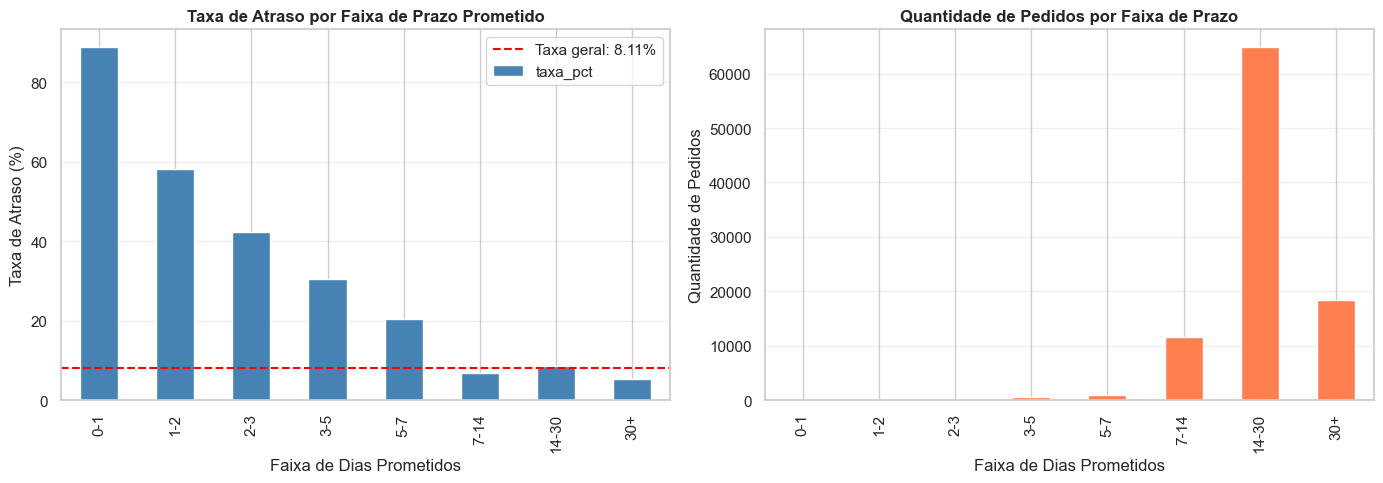

In [14]:
# Criar bins de prazo prometido para análise
bins = [0, 1, 2, 3, 5, 7, 14, 30, 300]
labels = ['0-1', '1-2', '2-3', '3-5', '5-7', '7-14', '14-30', '30+']
orders_analysis['promised_bin'] = pd.cut(
    orders_analysis['promised_days'], 
    bins=bins, 
    labels=labels,
    right=False
)

# Calcular taxa de atraso por faixa de prazo
delay_by_promise = (
    orders_analysis.groupby('promised_bin', observed=True)['is_late']
    .agg(['sum', 'count', 'mean'])
    .rename(columns={'sum': 'atrasos', 'count': 'total', 'mean': 'taxa_atraso'})
)

# Converter taxa para percentual
delay_by_promise['taxa_pct'] = (delay_by_promise['taxa_atraso'] * 100).round(2)

print("Taxa de atraso por faixa de prazo prometido:")
print(delay_by_promise[['total', 'atrasos', 'taxa_pct']])

# Visualizar com boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Taxa de atraso por faixa
ax1 = axes[0]
delay_by_promise['taxa_pct'].plot(kind='bar', ax=ax1, color='steelblue')
ax1.set_title('Taxa de Atraso por Faixa de Prazo Prometido', fontsize=12, fontweight='bold')
ax1.set_xlabel('Faixa de Dias Prometidos')
ax1.set_ylabel('Taxa de Atraso (%)')
ax1.axhline(y=late_rate, color='red', linestyle='--', label=f'Taxa geral: {late_rate:.2f}%')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Gráfico 2: Quantidade de pedidos por faixa
ax2 = axes[1]
delay_by_promise['total'].plot(kind='bar', ax=ax2, color='coral')
ax2.set_title('Quantidade de Pedidos por Faixa de Prazo', fontsize=12, fontweight='bold')
ax2.set_xlabel('Faixa de Dias Prometidos')
ax2.set_ylabel('Quantidade de Pedidos')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


**Conclusão da pergunta 2:** a taxa muda de forma consistente entre as faixas? Há faixas com poucas observações?

**Sim, há forte padrão crescente inverso:** 
- Prazos muito curtos (0-1 dias): 88.89% de atraso (18 pedidos - amostra muito pequena!)
- Prazos curtos (1-7 dias): 20-58% de atraso
- Prazos médios (7-14 dias): 6.76% de atraso
- Prazos longos (14+ dias): 5-8.6% de atraso

**Faixas com poucas observações:** sim, as faixas 0-5 dias têm < 1000 pedidos cada (especialmente 0-1 com apenas 18). As faixas 14-30 e 30+ dominam com ~83 mil pedidos.

**Implicação:** o prazo prometido é um **preditor muito forte** do atraso. Devemos incluir `promised_days` como feature contínua e/ou criar bins. Considerar transformações (log) e possíveis interações com região/vendedor.

# Pergunta 3: Pedidos maiores ou mais complexos atrasam mais?

**Hipótese:** pedidos com mais itens ou vendedores apresentam maior complexidade logística e maior risco.

Estatísticas por status de atraso:

Por item_count (quantidade de itens):
        item_count                    
            median      mean       std
is_late                               
0              1.0  1.144759  0.541904
1              1.0  1.113468  0.502167

Por seller_count (quantidade de vendedores):
        seller_count                    
              median      mean       std
is_late                                 
0                1.0  1.014927  0.128051
1                1.0  1.002300  0.047906

Por total_price (preço total):
        total_price                        
             median        mean         std
is_late                                    
0              85.5  136.067449  207.457719
1              89.9  148.085933  226.185232


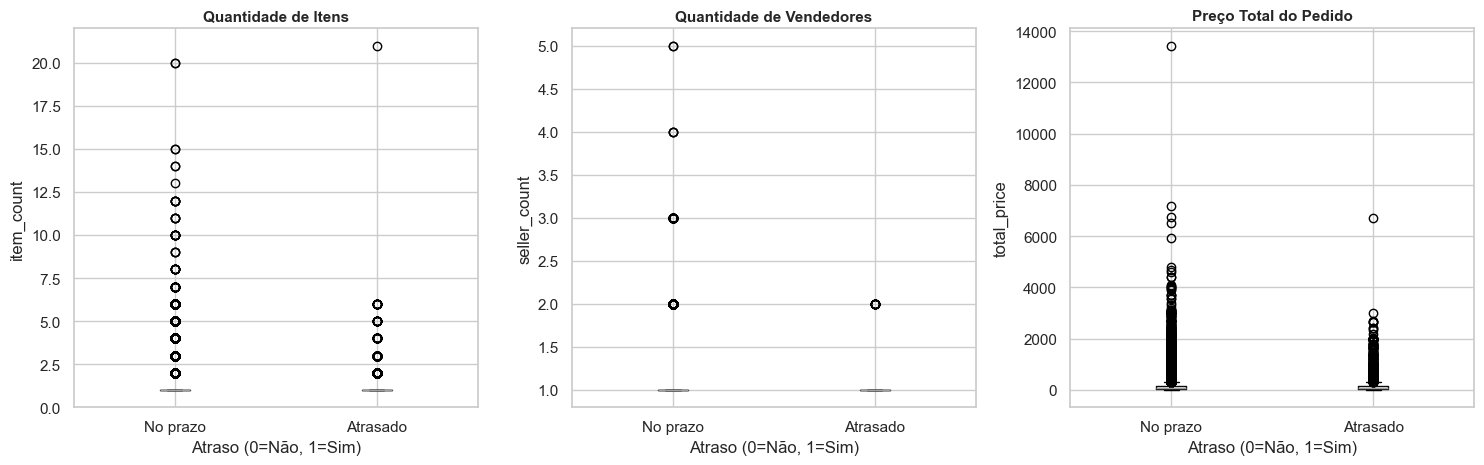



Teste de Mann-Whitney U (verifica se as distribuições são diferentes):
item_count: p-value = 0.000000 (significativo)
seller_count: p-value = 0.000000 (significativo)
total_price: p-value = 0.000000 (significativo)


In [15]:
# Comparar medianas e distribuições
complexity_vars = ['item_count', 'seller_count', 'total_price']

print("Estatísticas por status de atraso:")
print("\nPor item_count (quantidade de itens):")
print(orders_analysis.groupby('is_late')[['item_count']].agg(['median', 'mean', 'std']))

print("\nPor seller_count (quantidade de vendedores):")
print(orders_analysis.groupby('is_late')[['seller_count']].agg(['median', 'mean', 'std']))

print("\nPor total_price (preço total):")
print(orders_analysis.groupby('is_late')[['total_price']].agg(['median', 'mean', 'std']))

# Visualizar com boxplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

vars_to_plot = ['item_count', 'seller_count', 'total_price']
titles = ['Quantidade de Itens', 'Quantidade de Vendedores', 'Preço Total do Pedido']

for idx, (var, title) in enumerate(zip(vars_to_plot, titles)):
    ax = axes[idx]
    # Boxplot
    orders_analysis.boxplot(column=var, by='is_late', ax=ax)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Atraso (0=Não, 1=Sim)')
    ax.set_ylabel(var)
    plt.sca(ax)
    plt.xticks([1, 2], ['No prazo', 'Atrasado'])

plt.suptitle('')  # Remove o título automático
plt.tight_layout()
plt.show()

# Teste estatístico de Mann-Whitney U (para verificar diferenças significativas)
from scipy.stats import mannwhitneyu

print("\n\nTeste de Mann-Whitney U (verifica se as distribuições são diferentes):")
for var in complexity_vars:
    group_0 = orders_analysis[orders_analysis['is_late'] == 0][var]
    group_1 = orders_analysis[orders_analysis['is_late'] == 1][var]
    stat, p_value = mannwhitneyu(group_0, group_1)
    print(f"{var}: p-value = {p_value:.6f} {'(significativo)' if p_value < 0.05 else '(não significativo)'}")


**Conclusão da pergunta 3:** diferenças nas medianas parecem operacionalmente relevantes? Os boxplots mostram muita sobreposição?

**Diferenças pequenas mas significativas (p-value < 0.001):**
- `item_count`: mediana = 1 em ambos (sobreposição total). Média: 1.14 (no prazo) vs 1.11 (atrasado) - diferença negligenciável.
- `seller_count`: mediana = 1 em ambos. Distribuição muito similar (p-value significativo mas efeito fraco).
- `total_price`: mediana ≈ 85-90 em ambos. Média: 136 (no prazo) vs 148 (atrasado) - diferença ~8.8%.

**Boxplots mostram sobreposição massiva** para item_count e seller_count. O preço tem ligeiramente mais separação mas ainda com grande sobreposição.

**Implicação:** embora estatisticamente significantes (grande N = 96k), as diferenças **não são operacionalmente relevantes** para estes indicadores sozinhos. Complexidade logística não está bem capturada por item_count/seller_count. Estas variáveis provavelmente terão baixo poder preditivo comparadas a prazo. Considerar features derivadas (preço por item, densidade de itens) ou interações.

# Pergunta 4: O risco varia geograficamente?

**Hipótese:** alguns estados apresentam maior risco devido à distância ou à infraestrutura logística.

Para evitar conclusões instáveis, mostraremos apenas estados com pelo menos 100 pedidos no recorte.

Total de estados: 27
Estados com >= 100 pedidos: 24

Taxa de atraso por estado (ordenado do maior para o menor risco):
   customer_state  total  late_count  late_pct
1              AL    397          95     23.93
9              MA    716         141     19.69
16             PI    476          76     15.97
5              CE   1278         196     15.34
24             SE    335          51     15.22
4              BA   3256         457     14.04
18             RJ  12348        1664     13.48
26             TO    274          35     12.77
13             PA    946         117     12.37
7              ES   1995         244     12.23
11             MS    701          81     11.55
14             PB    517          57     11.03
15             PE   1593         172     10.80
19             RN    474          51     10.76
23             SC   3546         346      9.76
8              GO   1957         160      8.18
22             RS   5342         382      7.15
6              DF   2080         14

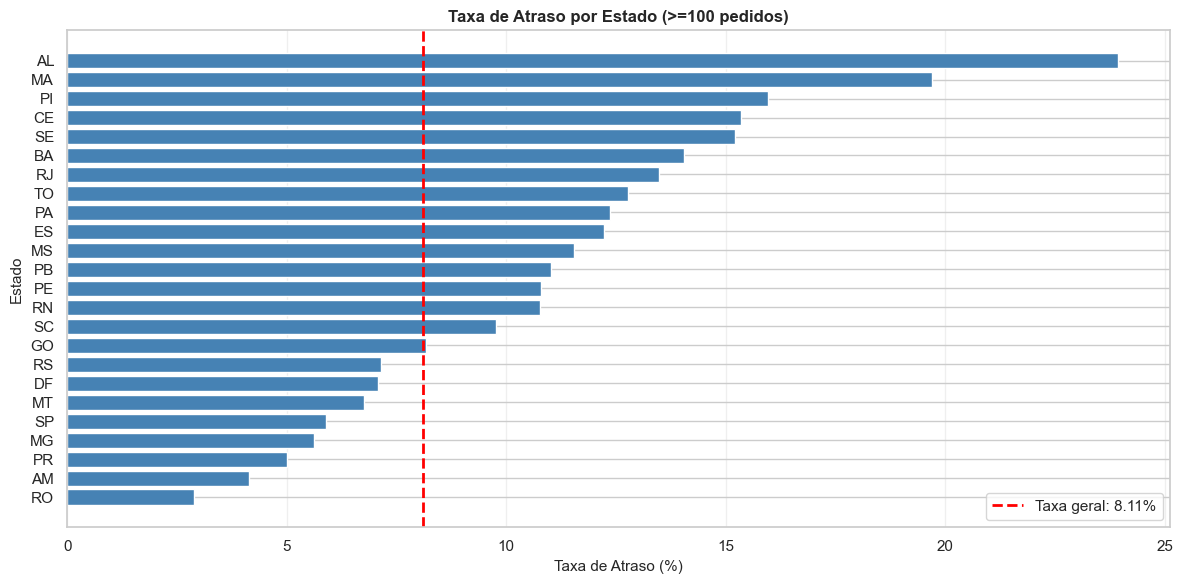


Variabilidade geográfica:
Menor taxa de atraso: 2.88% (RO)
Maior taxa de atraso: 23.93% (AL)
Diferença: 21.05 pontos percentuais


In [16]:
# Análise de risco por estado (apenas estados com >= 100 pedidos)
state_stats = (
    orders_analysis.groupby('customer_state')
    .agg(
        late_count=('is_late', 'sum'),
        total=('is_late', 'size'),
        late_rate=('is_late', 'mean')
    )
    .reset_index()
)

# Converter taxa para percentual
state_stats['late_pct'] = (state_stats['late_rate'] * 100).round(2)

# Filtrar apenas estados com pelo menos 100 pedidos
state_stats_filtered = state_stats[state_stats['total'] >= 100].sort_values('late_pct', ascending=False)

print(f"Total de estados: {len(state_stats)}")
print(f"Estados com >= 100 pedidos: {len(state_stats_filtered)}")
print(f"\nTaxa de atraso por estado (ordenado do maior para o menor risco):")
print(state_stats_filtered[['customer_state', 'total', 'late_count', 'late_pct']])

# Gráfico de taxa de atraso por estado (apenas com >= 100 pedidos)
fig, ax = plt.subplots(figsize=(12, 6))
state_stats_filtered_sorted = state_stats_filtered.sort_values('late_pct', ascending=True)

ax.barh(state_stats_filtered_sorted['customer_state'], state_stats_filtered_sorted['late_pct'], color='steelblue')
ax.axvline(x=late_rate, color='red', linestyle='--', linewidth=2, label=f'Taxa geral: {late_rate:.2f}%')
ax.set_xlabel('Taxa de Atraso (%)', fontsize=11)
ax.set_ylabel('Estado', fontsize=11)
ax.set_title('Taxa de Atraso por Estado (>=100 pedidos)', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# Estatísticas resumidas por região (variabilidade geográfica)
print(f"\nVariabilidade geográfica:")
print(f"Menor taxa de atraso: {state_stats_filtered['late_pct'].min():.2f}% ({state_stats_filtered.loc[state_stats_filtered['late_pct'].idxmin(), 'customer_state']})")
print(f"Maior taxa de atraso: {state_stats_filtered['late_pct'].max():.2f}% ({state_stats_filtered.loc[state_stats_filtered['late_pct'].idxmax(), 'customer_state']})")
print(f"Diferença: {state_stats_filtered['late_pct'].max() - state_stats_filtered['late_pct'].min():.2f} pontos percentuais")


**Conclusão da pergunta 4:** localização pode ser útil, mas "estado" talvez esteja representando outros fatores não observados. Que fatores seriam esses?

**Sim, variação geográfica é grande:** taxa de atraso varia de **2.88% (RO) a 23.93% (AL)**, diferença de **21.05 pontos percentuais**. Nordeste (AL, MA, PI, CE) e Norte têm taxas altas; Sul (RO, PR, RS) e Sudeste (SP, MG) têm taxas baixas.

**Fatores que "estado" pode estar representando (confundidores):**
- Distância/infraestrutura logística: estados remotos (MA, PA, TO) têm pior infraestrutura.
- Perfil de vendedores: vendedores no Sul podem ter melhor eficiência operacional.
- Padrão de compra: prazos prometidos podem variar por região.
- Concentração de centros de distribuição: maior em SP/MG/RJ.
- Tipo de produto: alguns estados podem comprar itens de maior complexidade.
- Eficiência do correio/transportadoras: varia regionalmente.

**Implicação:** incluir `customer_state` como feature categórica (one-hot ou target-encoding). Cuidado com *data leakage*: estado pode ser proxy para variáveis não disponíveis na aprovação do pagamento. Considerar interações estado × prazo, estado × preço.

# Pergunta 5: O momento da compra está associado ao atraso?

**Hipótese:** determinados meses enfrentam maior pressão logística e apresentam maior taxa de atraso.

Taxa de atraso por mês de compra:
   month_name  total  late_count  late_pct
0         Jan   7817         487      6.23
1         Fev   8196        1101     13.43
2         Mar   9549        1638     17.15
3         Abr   9101         542      5.96
4         Mai  10294         684      6.64
5         Jun   9231         204      2.21
6         Jul  10028         409      4.08
7         Ago  10544         799      7.58
8         Set   4151         217      5.23
9         Out   4743         240      5.06
10        Nov   7288        1043     14.31
11        Dez   5514         462      8.38

Taxa de atraso por dia da semana:
  day_name  total  late_count  late_pct
0      Seg  15701        1421      9.05
1      Ter  15502        1316      8.49
2      Qua  15074        1176      7.80
3      Qui  14320        1084      7.57
4      Sex  13681        1156      8.45
5      Sab  10547         802      7.60
6      Dom  11631         871      7.49


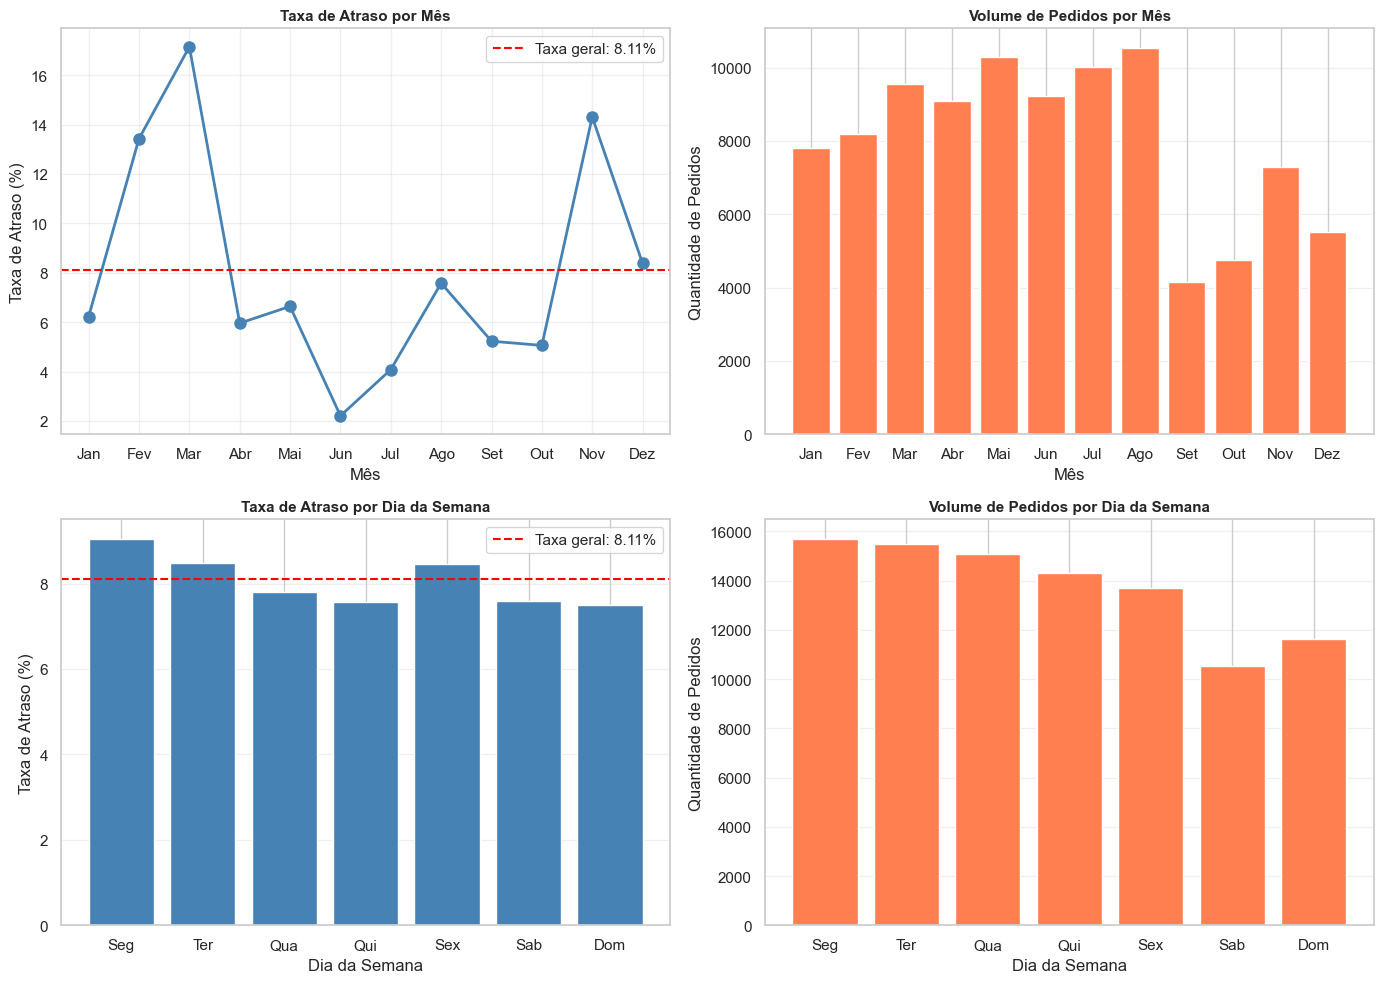


Variabilidade por mês:
Menor taxa: 2.21% (Jun)
Maior taxa: 17.15% (Mar)
Diferença: 14.94 pontos percentuais

Variabilidade por dia da semana:
Menor taxa: 7.49% (Dom)
Maior taxa: 9.05% (Seg)
Diferença: 1.56 pontos percentuais


In [17]:
# Análise de sazonalidade por mês
monthly_stats = (
    orders_analysis.groupby('purchase_month')
    .agg(
        late_count=('is_late', 'sum'),
        total=('is_late', 'size'),
        late_rate=('is_late', 'mean')
    )
    .reset_index()
)
monthly_stats['late_pct'] = (monthly_stats['late_rate'] * 100).round(2)
monthly_stats['month_name'] = monthly_stats['purchase_month'].map({
    1: 'Jan', 2: 'Fev', 3: 'Mar', 4: 'Abr', 5: 'Mai', 6: 'Jun',
    7: 'Jul', 8: 'Ago', 9: 'Set', 10: 'Out', 11: 'Nov', 12: 'Dez'
})

print("Taxa de atraso por mês de compra:")
print(monthly_stats[['month_name', 'total', 'late_count', 'late_pct']])

# Análise por dia da semana
weekday_stats = (
    orders_analysis.groupby('purchase_weekday')
    .agg(
        late_count=('is_late', 'sum'),
        total=('is_late', 'size'),
        late_rate=('is_late', 'mean')
    )
    .reset_index()
)
weekday_stats['late_pct'] = (weekday_stats['late_rate'] * 100).round(2)
weekday_stats['day_name'] = weekday_stats['purchase_weekday'].map({
    0: 'Seg', 1: 'Ter', 2: 'Qua', 3: 'Qui', 4: 'Sex', 5: 'Sab', 6: 'Dom'
})

print("\nTaxa de atraso por dia da semana:")
print(weekday_stats[['day_name', 'total', 'late_count', 'late_pct']])

# Visualização
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Gráfico 1: Taxa de atraso por mês
ax1 = axes[0, 0]
ax1.plot(monthly_stats['month_name'], monthly_stats['late_pct'], marker='o', linewidth=2, markersize=8, color='steelblue')
ax1.axhline(y=late_rate, color='red', linestyle='--', label=f'Taxa geral: {late_rate:.2f}%')
ax1.set_title('Taxa de Atraso por Mês', fontsize=11, fontweight='bold')
ax1.set_xlabel('Mês')
ax1.set_ylabel('Taxa de Atraso (%)')
ax1.legend()
ax1.grid(alpha=0.3)

# Gráfico 2: Quantidade de pedidos por mês
ax2 = axes[0, 1]
ax2.bar(monthly_stats['month_name'], monthly_stats['total'], color='coral')
ax2.set_title('Volume de Pedidos por Mês', fontsize=11, fontweight='bold')
ax2.set_xlabel('Mês')
ax2.set_ylabel('Quantidade de Pedidos')
ax2.grid(axis='y', alpha=0.3)

# Gráfico 3: Taxa de atraso por dia da semana
ax3 = axes[1, 0]
ax3.bar(weekday_stats['day_name'], weekday_stats['late_pct'], color='steelblue')
ax3.axhline(y=late_rate, color='red', linestyle='--', label=f'Taxa geral: {late_rate:.2f}%')
ax3.set_title('Taxa de Atraso por Dia da Semana', fontsize=11, fontweight='bold')
ax3.set_xlabel('Dia da Semana')
ax3.set_ylabel('Taxa de Atraso (%)')
ax3.legend()
ax3.grid(axis='y', alpha=0.3)

# Gráfico 4: Volume de pedidos por dia da semana
ax4 = axes[1, 1]
ax4.bar(weekday_stats['day_name'], weekday_stats['total'], color='coral')
ax4.set_title('Volume de Pedidos por Dia da Semana', fontsize=11, fontweight='bold')
ax4.set_xlabel('Dia da Semana')
ax4.set_ylabel('Quantidade de Pedidos')
ax4.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Análise de variabilidade
print(f"\nVariabilidade por mês:")
print(f"Menor taxa: {monthly_stats['late_pct'].min():.2f}% ({monthly_stats.loc[monthly_stats['late_pct'].idxmin(), 'month_name']})")
print(f"Maior taxa: {monthly_stats['late_pct'].max():.2f}% ({monthly_stats.loc[monthly_stats['late_pct'].idxmax(), 'month_name']})")
print(f"Diferença: {monthly_stats['late_pct'].max() - monthly_stats['late_pct'].min():.2f} pontos percentuais")

print(f"\nVariabilidade por dia da semana:")
print(f"Menor taxa: {weekday_stats['late_pct'].min():.2f}% ({weekday_stats.loc[weekday_stats['late_pct'].idxmin(), 'day_name']})")
print(f"Maior taxa: {weekday_stats['late_pct'].max():.2f}% ({weekday_stats.loc[weekday_stats['late_pct'].idxmax(), 'day_name']})")
print(f"Diferença: {weekday_stats['late_pct'].max() - weekday_stats['late_pct'].min():.2f} pontos percentuais")


**Conclusão da pergunta 5:** há indícios de sazonalidade? Compare também a quantidade de pedidos por mês antes de concluir.

**Sim, sazonalidade forte por MÊS:**
- **Picos de atraso:** Março (17.15%), Fevereiro (13.43%), Novembro (14.31%) - períodos de demanda alta (Carnaval, Black Friday, buscas de verão).
- **Vales de atraso:** Junho (2.21%), Julho (4.08%), Setembro (5.23%) - períodos de demanda baixa.
- Diferença: 17.15% - 2.21% = **14.94 pontos percentuais** (variação 8x).

**Sazonalidade fraca por DIA DA SEMANA:**
- Segunda (9.05%) ligeiramente acima de quinta-domingo (7.49-7.80%).
- Diferença: apenas 1.56 pontos (1.2x) - praticamente negligenciável.

**Quantidade de pedidos**: novembro pico de atrasos coincide com volume moderado (7.3k), março pico coincide com volume alto (9.5k). Junho tem volume alto (9.2k) mas mínima taxa - sugerindo que volume não explica atraso, e sim a pressão logística real do período.

**Implicação:** incluir `purchase_month` como feature categórica. **Não usar `purchase_weekday` isoladamente** (efeito fraco). Considerar codificação cíclica (sin/cos) se usar contínuo. Explorar interações: mês × prazo (março + prazos curtos = risco muito alto). Possível oportunidade operacional: alocar mais recursos em fevereiro-março-novembro.